# 02 — Phân bố không gian, khu vực & Timezone

Câu hỏi:
1. Dữ liệu nằm ở đâu? Bao nhiêu % ở Bắc Kinh, bao nhiêu % ngoài Trung Quốc?
2. Mỗi điểm thuộc timezone nào? Có DST không? Có user nào đi qua nhiều timezone?
3. Mật độ trong Bắc Kinh: hotspot ở đâu (gợi ý về nhóm user — sinh viên/nhân viên Microsoft Research Asia ở Haidian).
4. Phạm vi di chuyển của từng user (radius of gyration).

Timestamp gốc là **UTC** → cần timezone đúng để suy ra giờ địa phương (đêm/ngày làm việc) — đầu vào cốt lõi cho home/office.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from utils import BEIJING_BBOX, ROOT, add_geo, haversine, load_points, savefig, setup_style

setup_style()
pts = load_points(["user", "traj_id", "lat", "lon", "ts_utc"])
pts = pts[pts.lat.between(-90, 90)]  # bỏ 1 điểm lat lỗi (xem NB01)
print(len(pts))

24876977


## 1. Phạm vi toàn cục

In [2]:
print(pts[["lat", "lon"]].describe(percentiles=[.001, .01, .5, .99, .999]).T)

              count     mean     std       min      0.1%        1%      50%      99%    99.9%      max
lat 24,876,977.0000  38.9799  4.0699    1.0440    1.8759   22.5980  39.9750  46.6013  59.8982  64.7520
lon 24,876,977.0000 112.3597 27.1796 -179.9696 -149.3597 -115.1695 116.3342 121.6345 127.9423 179.9969


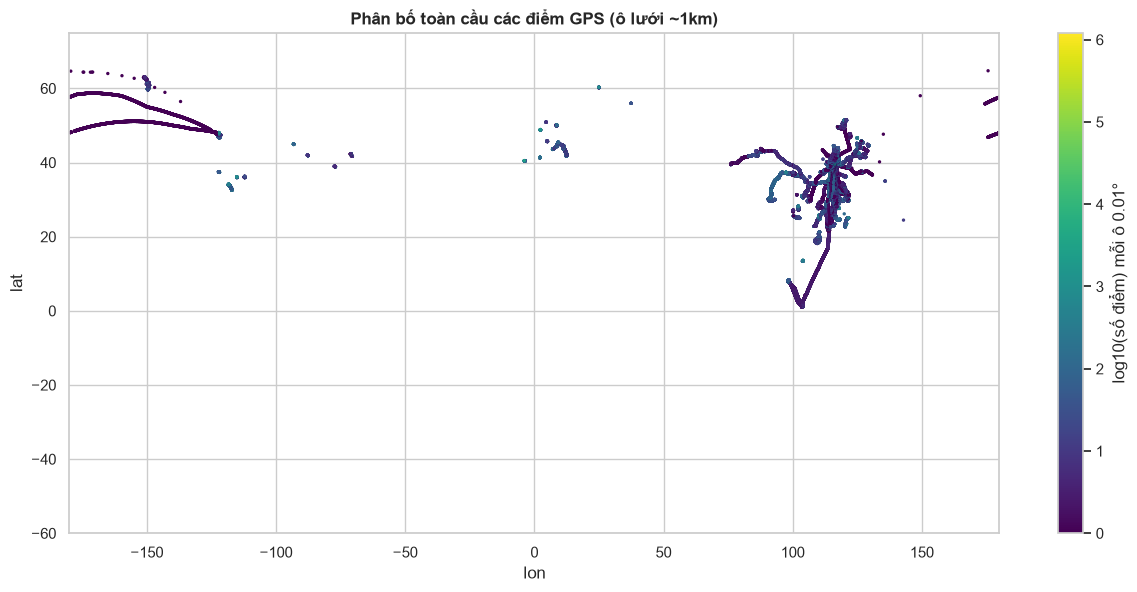

In [3]:
# Gom về lưới 0.01° (~1km) để vẽ nhanh toàn cầu
cell = pts.assign(clat=(pts.lat / 0.01).round() * 0.01, clon=(pts.lon / 0.01).round() * 0.01) \
    .groupby(["clat", "clon"]).agg(n=("user", "size"), n_users=("user", "nunique")).reset_index()
fig, ax = plt.subplots(figsize=(15, 6.5))
sc = ax.scatter(cell.clon, cell.clat, s=2, c=np.log10(cell.n), cmap="viridis")
plt.colorbar(sc, label="log10(số điểm) mỗi ô 0.01°")
ax.set_xlim(-180, 180); ax.set_ylim(-60, 75)
ax.set_title("Phân bố toàn cầu các điểm GPS (ô lưới ~1km)")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
savefig("02_world"); plt.show()

## 2. Gán timezone & thành phố
`add_geo` (trong `utils.py`) tra `timezonefinder` (offline, theo polygon timezone) cho **từng toạ độ duy nhất**, sau khi làm tròn
4 chữ số (~11 m), rồi tính UTC offset thật cho từng điểm (có xét DST cho các tz như America/*, Europe/*).

Trước khi chọn cách này, so sánh với cách nhanh hơn là tra trên lưới 0,05° (~5 km) rồi join về điểm: tra chính xác tốn bao lâu,
và lưới sai bao nhiêu?

In [4]:
import time
from timezonefinder import TimezoneFinder

tf = TimezoneFinder()
uniq = pd.DataFrame({"lat": pts.lat.round(4), "lon": pts.lon.round(4)}).drop_duplicates()
t0 = time.time()
smp = uniq.sample(300_000, random_state=0)
exact = [tf.timezone_at(lat=a, lng=o) or "Unknown" for a, o in zip(smp.lat, smp.lon)]
t_exact = (time.time() - t0) / len(smp) * len(uniq)
grid = [tf.timezone_at(lat=a, lng=o) or "Unknown" for a, o in zip((smp.lat / .05).round() * .05, (smp.lon / .05).round() * .05)]
ref = pd.Timestamp("2009-01-15", tz="UTC")
offset_of = lambda z: np.nan if z == "Unknown" else ref.tz_convert(z).utcoffset().total_seconds() / 3600
cmp_ = pd.DataFrame({"grid": grid, "exact": exact})
bad = cmp_[cmp_.grid != cmp_.exact]
n_off = sum(offset_of(a) != offset_of(b) for a, b in zip(bad.grid, bad.exact))
print(f"{len(uniq):,} toạ độ duy nhất; ước tính tra chính xác toàn bộ mất ~{t_exact:.0f} s")
print(f"Lưới 0,05° khác tra chính xác: {len(bad)}/{len(smp)} = {len(bad) / len(smp):.3%}; trong đó khác offset: {n_off}")
print(bad.value_counts().head(6).to_string())

4,733,954 toạ độ duy nhất; ước tính tra chính xác toàn bộ mất ~4 s
Lưới 0,05° khác tra chính xác: 303/300000 = 0.101%; trong đó khác offset: 196
grid            exact         
Asia/Pyongyang  Asia/Shanghai     96
Asia/Chita      Asia/Shanghai     85
Asia/Hong_Kong  Asia/Shanghai     51
Europe/Paris    Europe/Monaco     39
Europe/Rome     Europe/Vatican    10
Asia/Singapore  Asia/Jakarta       6


**Insight:** lưới sai ở vùng biên giới (Bắc Kinh–Triều Tiên/Nga do ô lưới lớn, Hồng Kông/Ma Cao), và phần lớn chỗ sai là **sai offset**.
Tra chính xác chỉ tốn vài giây nên không có lý do dùng lưới. Các notebook EDA từ đây dùng tra chính xác.

In [5]:
pts = add_geo(pts)
print("Số timezone:", pts.tz.nunique(), "| điểm không xác định được tz:", (pts.tz == "Unknown").sum())

Số timezone: 41 | điểm không xác định được tz: 0


In [6]:
tz_stats = (pts.groupby("tz", observed=True)
            .agg(n_points=("user", "size"), n_users=("user", "nunique"), n_traj=("traj_id", "nunique"))
            .sort_values("n_points", ascending=False))
tz_stats["pct_points"] = tz_stats.n_points / len(pts) * 100
tz_stats

,n_points,n_users,n_traj,pct_points
tz,,,,
Asia/Shanghai,24105108,181,17583,96.8973
America/Los_Angeles,223275,7,87,0.8975
Asia/Taipei,71798,3,12,0.2886
Europe/Rome,60948,2,7,0.2450
Asia/Urumqi,54546,3,8,0.2193
Asia/Bangkok,51900,1,4,0.2086
Europe/Paris,51855,2,12,0.2084
Europe/Madrid,36772,2,9,0.1478
Asia/Hong_Kong,30521,5,17,0.1227


In [7]:
# Phân bố UTC offset (đã xét DST)
pts.groupby("utc_offset_h").agg(n=("user", "size"), users=("user", "nunique"),
                               tzs=("tz", lambda s: ", ".join(sorted(s.unique().astype(str))[:6])))

,n,users,tzs
utc_offset_h,,,
-12.0000,377,2,Etc/GMT+12
-11.0000,789,2,Etc/GMT+11
-10.0000,808,2,Etc/GMT+10
-9.0000,1019,2,"America/Anchorage, Etc/GMT+9"
-8.0000,100558,6,"America/Anchorage, America/Los_Angeles, Americ..."
-7.0000,153292,6,"America/Los_Angeles, America/Phoenix"
-6.0000,395,1,America/Chicago
-5.0000,17566,2,America/Chicago
-4.0000,23619,2,America/New_York


In [8]:
print("Asia/Shanghai có DST không? offset duy nhất:",
      pts.loc[pts.tz == "Asia/Shanghai", "utc_offset_h"].unique())
print(f"% điểm có offset = +8: {(pts.utc_offset_h == 8).mean():.3%}")

Asia/Shanghai có DST không? offset duy nhất: [8.]
% điểm có offset = +8: 97.475%


**Insight:** Gần như toàn bộ dữ liệu là UTC+8 (Trung Quốc không có DST) → chuyển sang giờ địa phương chỉ cần +8h cho phần lớn điểm,
nhưng không được hard-code: các điểm ở Mỹ/Châu Âu/Nhật... cần offset riêng (có DST). Pipeline nên gán timezone theo toạ độ.

### 2.1 Khu vực (thành phố)

In [9]:
city_stats = (pts.groupby("city", observed=True)
              .agg(n_points=("user", "size"), n_users=("user", "nunique"), n_traj=("traj_id", "nunique"))
              .sort_values("n_points", ascending=False))
city_stats["pct_points"] = city_stats.n_points / len(pts) * 100
city_stats.head(30)

,n_points,n_users,n_traj,pct_points
city,,,,
Beijing,19990185,179,16550,80.3562
Other,2280119,76,696,9.1656
Chengde,220204,22,78,0.8852
Qinhuangdao,193569,23,84,0.7781
Tianjin,189785,49,197,0.7629
Shanghai,142148,16,75,0.5714
Tangshan,111703,23,51,0.4490
Wuhan,104932,18,39,0.4218
Hangzhou,98019,5,37,0.3940


% điểm trong bbox Bắc Kinh {'lat_min': 39.6, 'lat_max': 40.3, 'lon_min': 115.9, 'lon_max': 116.8}: 78.06%
User có >= 90% điểm ở Bắc Kinh: 98 / 182
User có < 50% điểm ở Bắc Kinh: 31


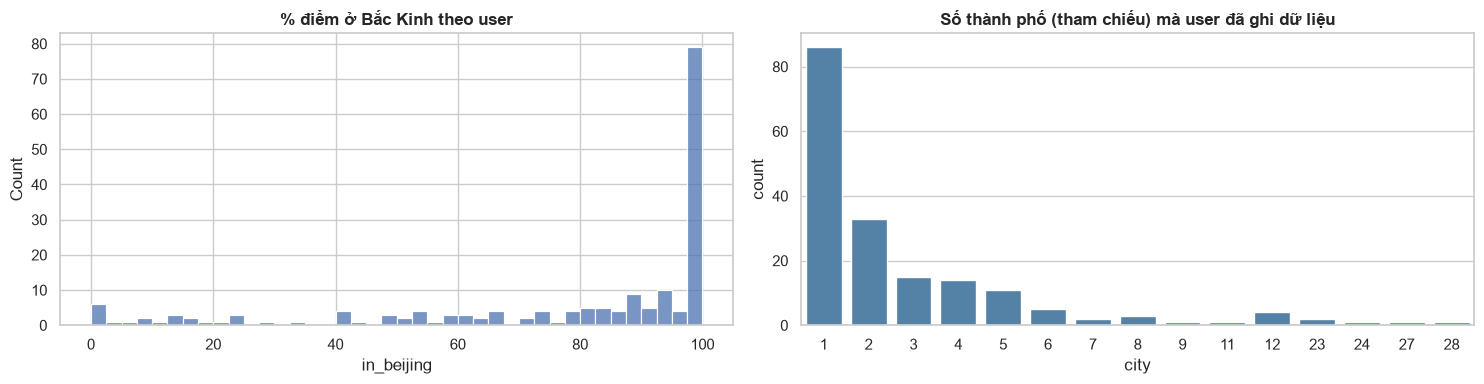

In [10]:
bj = pts.in_beijing.to_numpy()
print(f"% điểm trong bbox Bắc Kinh {BEIJING_BBOX}: {bj.mean():.2%}")
user_bj = pts.groupby("user").in_beijing.mean()
print(f"User có >= 90% điểm ở Bắc Kinh: {(user_bj >= .9).sum()} / {len(user_bj)}")
print(f"User có < 50% điểm ở Bắc Kinh: {(user_bj < .5).sum()}")
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(user_bj * 100, bins=40, ax=ax[0]); ax[0].set_title("% điểm ở Bắc Kinh theo user")
n_city = pts[pts.city != "Other"].groupby("user").city.nunique()
sns.countplot(x=n_city, ax=ax[1], color="steelblue"); ax[1].set_title("Số thành phố (tham chiếu) mà user đã ghi dữ liệu")
plt.tight_layout(); savefig("02_user_beijing_share")

In [11]:
# User ngoài Bắc Kinh: họ ở đâu?
non_bj_users = user_bj[user_bj < 0.5].index
(pts[pts.user.isin(non_bj_users)].groupby(["user", "city"], observed=True).size()
 .rename("n").reset_index().sort_values(["user", "n"], ascending=[True, False])
 .groupby("user").head(3))

,user,city,n
14,10,Other,402174
1,10,Beijing,254826
22,10,Tianjin,104936
28,12,Beijing,62339
31,12,Other,45905
...,...,...,...
168,172,Xi'an,6810
166,172,Beijing,758
172,180,Other,40802
169,180,Baoding,2262


In [12]:
# Điểm "Other" lớn ở đâu? (ô 1° có nhiều điểm nhưng không gần thành phố tham chiếu)
o = pts[pts.city == "Other"]
(o.assign(lat1=o.lat.round(0), lon1=o.lon.round(0)).groupby(["lat1", "lon1"])
 .agg(n=("user", "size"), users=("user", "nunique"), tz=("tz", "first")).sort_values("n", ascending=False).head(15))

,,n,users,tz
lat1,lon1,,,
32.0000,117.0000,58016,8,Asia/Shanghai
47.0000,125.0000,57485,1,Asia/Shanghai
23.0000,108.0000,53913,1,Asia/Shanghai
41.0000,117.0000,46664,29,Asia/Shanghai
8.0000,98.0000,42518,1,Asia/Bangkok
42.0000,118.0000,37189,10,Asia/Shanghai
34.0000,117.0000,36066,10,Asia/Shanghai
33.0000,-117.0000,35232,2,America/Los_Angeles
43.0000,117.0000,34742,7,Asia/Shanghai


## 3. Mật độ trong Bắc Kinh

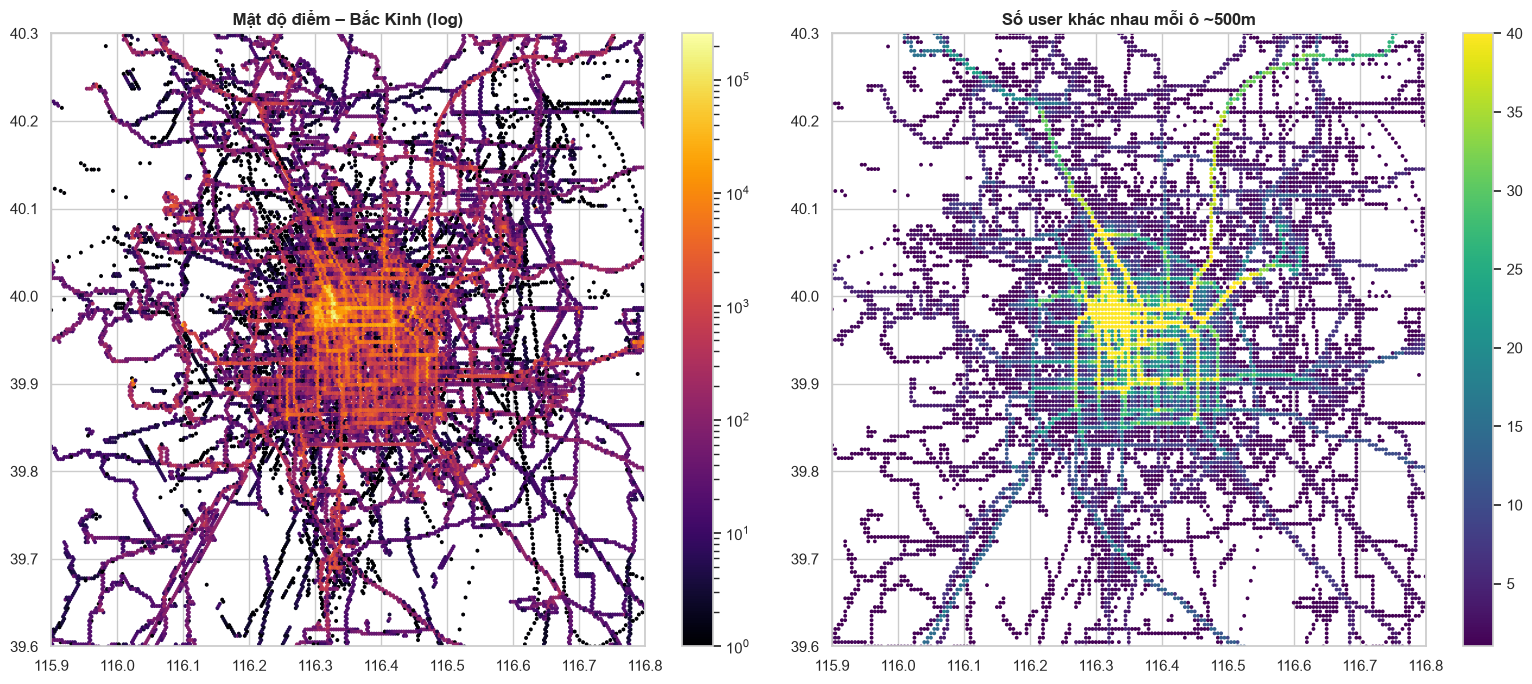

In [13]:
b = pts[pts.in_beijing]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
hb = axes[0].hexbin(b.lon, b.lat, gridsize=250, bins="log", cmap="inferno", mincnt=1)
axes[0].set_title("Mật độ điểm – Bắc Kinh (log)"); plt.colorbar(hb, ax=axes[0])
# số user khác nhau mỗi ô ~ 500m → hotspot "chung", không bị 1 power-user chi phối
bc = b.assign(cx=(b.lon / 0.005).round(), cy=(b.lat / 0.005).round()).groupby(["cx", "cy"]).user.nunique().reset_index()
sc = axes[1].scatter(bc.cx * 0.005, bc.cy * 0.005, c=bc.user, s=3, cmap="viridis", vmax=40)
axes[1].set_title("Số user khác nhau mỗi ô ~500m"); plt.colorbar(sc, ax=axes[1])
for a in axes: a.set_xlim(BEIJING_BBOX["lon_min"], BEIJING_BBOX["lon_max"]); a.set_ylim(BEIJING_BBOX["lat_min"], BEIJING_BBOX["lat_max"])
plt.tight_layout(); savefig("02_beijing_density"); plt.show()

In [14]:
# Top ô ~500m theo số user (hotspot chung)
top_cells = bc.sort_values("user", ascending=False).head(10).assign(lat=lambda d: d.cy * 0.005, lon=lambda d: d.cx * 0.005)
top_cells[["lat", "lon", "user"]]

,lat,lon,user
4778,39.9750,116.3300,165
4880,39.9750,116.3350,148
4682,39.9750,116.3250,138
4779,39.9800,116.3300,130
4780,39.9850,116.3300,121
4683,39.9800,116.3250,119
4684,39.9850,116.3250,117
4363,39.9750,116.3100,110
4781,39.9900,116.3300,109
4882,39.9850,116.3350,107


**Insight:** hotspot chung nằm ở khu Haidian (~39.98N, 116.31E — quanh Zhongguancun / Tsinghua / PKU / Microsoft Research Asia),
phù hợp với việc người tham gia chủ yếu là nhân viên/sinh viên MSRA. → "office" của nhiều user có thể **trùng nhau**
(cùng toà nhà) — đây vừa là cơ hội kiểm tra chéo (sanity check) vừa là bias (model có thể học "office = Haidian").

## 4. Phạm vi di chuyển từng user (radius of gyration)

       rog_all_km  rog_beijing_km
count    182.0000        179.0000
mean     284.8059          7.3475
std      656.4063          4.3610
min        0.0672          0.0128
25%        5.7810          4.5000
50%       32.2307          6.6864
75%      359.9309          9.6403
90%      669.1705         13.7543
max    4,692.2628         19.9506


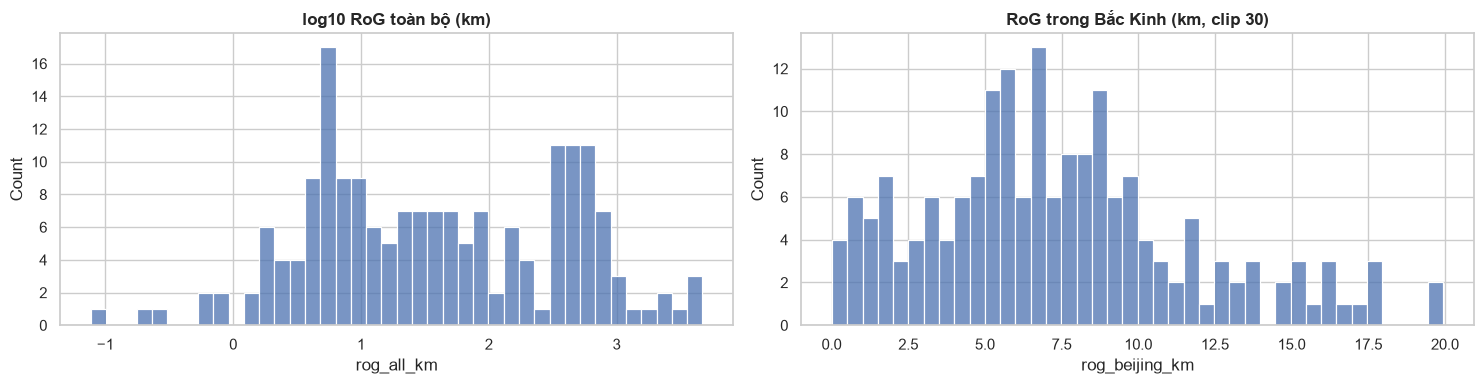

In [15]:
def rog(g):
    la, lo = g.lat.to_numpy(), g.lon.to_numpy()
    return np.sqrt(np.mean(haversine(la, lo, np.median(la), np.median(lo)) ** 2)) / 1000

sample = pts[pts.groupby("user").cumcount() % 10 == 0]  # thưa 1/10 cho nhanh
r_all = sample.groupby("user").apply(rog).rename("rog_all_km")
r_bj = sample[sample.in_beijing].groupby("user").apply(rog).rename("rog_beijing_km")
rg = pd.concat([r_all, r_bj], axis=1)
print(rg.describe(percentiles=[.25, .5, .75, .9]))
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(np.log10(rg.rog_all_km + 0.01), bins=40, ax=ax[0]); ax[0].set_title("log10 RoG toàn bộ (km)")
sns.histplot(rg.rog_beijing_km.clip(upper=30), bins=40, ax=ax[1]); ax[1].set_title("RoG trong Bắc Kinh (km, clip 30)")
plt.tight_layout(); savefig("02_radius_gyration")

## 5. Ghi chú hệ toạ độ
Header file ghi **WGS 84**. Bản đồ Trung Quốc (AMap/Baidu) dùng GCJ-02/BD-09 lệch ~300–700m so với WGS84 → khi
kiểm tra thủ công home/office trên bản đồ Trung Quốc phải chuyển hệ, còn với OpenStreetMap (WGS84) thì vẽ trực tiếp.

## 6. Bản đồ tương tác (folium heatmap) & lưu kết quả

In [16]:
import folium
from folium.plugins import HeatMap

hm = b.sample(200_000, random_state=0)
m = folium.Map(location=[39.95, 116.35], zoom_start=11, tiles="OpenStreetMap")
HeatMap(hm[["lat", "lon"]].to_numpy().tolist(), radius=6, blur=8, min_opacity=0.3).add_to(m)
out = ROOT / "EDA" / "outputs"; out.mkdir(exist_ok=True)
m.save(out / "02_beijing_heatmap.html")
print("saved", out / "02_beijing_heatmap.html")

saved /Users/nguyendat/Documents/GeolifeGPS-trajectory/EDA/outputs/02_beijing_heatmap.html
